1. Data Import & Cleaning

In [ ]:
!pip install -q "kagglehub[pandas-datasets]"

In [ ]:
# Install dependencies as needed:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import Image as IPyImage
import numpy as np

In [ ]:
# Set the path to the file you'd like to load
file_path = "amazon_products.csv"

# Load the latest version
df_product = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "asaniczka/amazon-products-dataset-2023-1-4m-products",
  "amazon_products.csv",
  # pandas_kwargs={"nrows": 20000}
)

display(df_product.head())

# Load the latest version
df_category = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "asaniczka/amazon-products-dataset-2023-1-4m-products",
  "amazon_categories.csv"
)

display(df_category)

/tmp/ipykernel_4589/1762996801.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_product = kagglehub.load_dataset(


Using Colab cache for faster access to the 'amazon-products-dataset-2023-1-4m-products' dataset.


,asin,title,imgUrl,productURL,stars,reviews,price,listPrice,category_id,isBestSeller,boughtInLastMonth
0,B014TMV5YE,"Sion Softside Expandable Roller Luggage, Black...",https://m.media-amazon.com/images/I/815dLQKYIY...,https://www.amazon.com/dp/B014TMV5YE,4.5,0,139.99,0.00,104,False,2000
1,B07GDLCQXV,Luggage Sets Expandable PC+ABS Durable Suitcas...,https://m.media-amazon.com/images/I/81bQlm7vf6...,https://www.amazon.com/dp/B07GDLCQXV,4.5,0,169.99,209.99,104,False,1000
2,B07XSCCZYG,Platinum Elite Softside Expandable Checked Lug...,https://m.media-amazon.com/images/I/71EA35zvJB...,https://www.amazon.com/dp/B07XSCCZYG,4.6,0,365.49,429.99,104,False,300
3,B08MVFKGJM,Freeform Hardside Expandable with Double Spinn...,https://m.media-amazon.com/images/I/91k6NYLQyI...,https://www.amazon.com/dp/B08MVFKGJM,4.6,0,291.59,354.37,104,False,400
4,B01DJLKZBA,Winfield 2 Hardside Expandable Luggage with Sp...,https://m.media-amazon.com/images/I/61NJoaZcP9...,https://www.amazon.com/dp/B01DJLKZBA,4.5,0,174.99,309.99,104,False,400


/tmp/ipykernel_4589/1762996801.py:15: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_category = kagglehub.load_dataset(


Using Colab cache for faster access to the 'amazon-products-dataset-2023-1-4m-products' dataset.


,id,category_name
0,1,Beading & Jewelry Making
1,2,Fabric Decorating
2,3,Knitting & Crochet Supplies
3,4,Printmaking Supplies
4,5,Scrapbooking & Stamping Supplies
...,...,...
243,262,"Xbox Series X & S Consoles, Games & Accessories"
244,263,PC Games & Accessories
245,264,Baby Girls' Clothing & Shoes
246,265,Boys' School Uniforms


In [ ]:
#Office Electronics ID
display(df_category[df_category["category_name"].str.contains("office", case=False)])


,id,category_name
66,72,Office Electronics


In [ ]:
# Set the random seed and the category id (Office Electronics)
SEED = 348
CAT_ID = 72

In [ ]:
# Keep only the products in our category
df_sub = df_product[df_product["category_id"] == CAT_ID].copy()
print("Rows after category filter:", len(df_sub))

# Start the cleaning log
cleaning_log = [{"step": "category filter (id 72)", "rows": len(df_sub)}]

Rows after category filter: 9480


,category_id,last_month_sales_units,num_items,id,category_name
0,170,10432300,4882,170,Kitchen & Dining
1,47,8012850,8669,47,Hair Care Products
2,162,7093350,4433,162,Industrial & Scientific
3,167,6875700,8523,167,Household Cleaning Supplies
4,49,6612150,8074,49,Skin Care Products
5,135,6138000,724,135,Health & Household
6,270,5858000,20846,270,Toys & Games
7,173,5356200,15437,173,Home Storage & Organization
8,180,4576650,8325,180,Dog Supplies
9,130,4289000,1942,130,Household Supplies


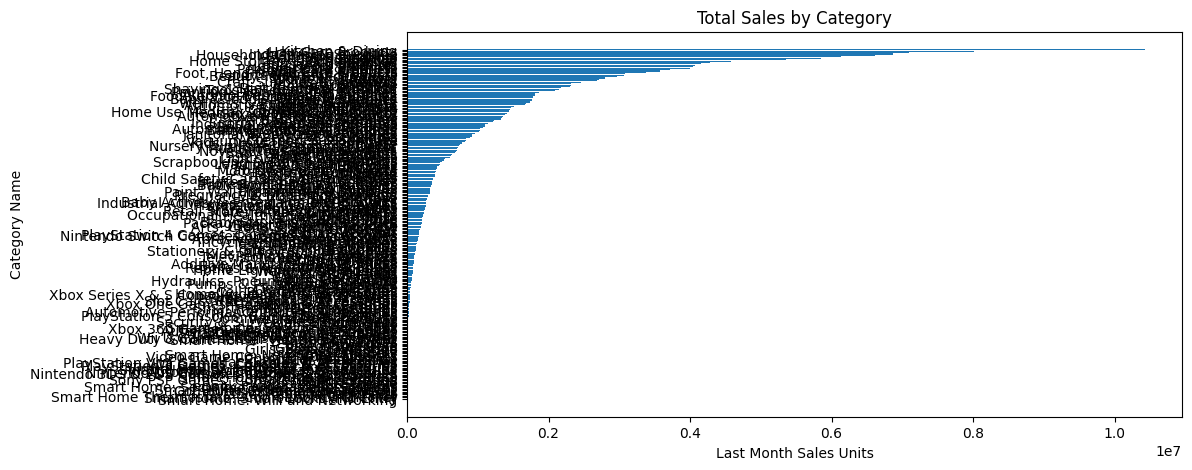

In [ ]:
# compute the total sales by category
df_sales_category=df_product.groupby("category_id").agg(
    last_month_sales_units=('boughtInLastMonth', 'sum'), num_items=('asin', 'count')).sort_values(
        by="last_month_sales_units", ascending=False).reset_index()

# merge with the category information
df_sales_category = df_sales_category.merge(df_category, left_on="category_id", right_on="id", how="inner")
display(df_sales_category.head(10))


plt.figure(figsize=(10, 5))
plt.barh(df_sales_category["category_name"], df_sales_category["last_month_sales_units"])
plt.xlabel("Last Month Sales Units")
plt.ylabel("Category Name")
plt.title("Total Sales by Category")
plt.gca().invert_yaxis() # To display the highest sales at the top
plt.show()

In [ ]:
# focus on one category, Office Electronics category category_id=72
df_product_sub = df_sub.reset_index(drop=True)

# display the first few row of imgUrl column
display(df_product_sub["imgUrl"].head())

# show the image located at this URL; [0] return the first image
display(IPyImage(url=df_product_sub["imgUrl"][0]))

#  remove items with missing imgUrl


,imgUrl
0,https://m.media-amazon.com/images/I/61jvFz3wwv...
1,https://m.media-amazon.com/images/I/71a7EOuH7z...
2,https://m.media-amazon.com/images/I/71bZkt3jB9...
3,https://m.media-amazon.com/images/I/71tZw0rUWT...
4,https://m.media-amazon.com/images/I/71bIPT6Clg...


In [ ]:
# check duplicates and missing values
print("Duplicate ASINs:", df_product_sub["asin"].duplicated().sum())
print(df_product_sub.isna().sum())

# summary statistics of the numeric columns
display(df_product_sub[["price", "listPrice", "stars", "reviews", "boughtInLastMonth"]].describe())

Duplicate ASINs: 0
asin                 0
title                0
imgUrl               0
productURL           0
stars                0
reviews              0
price                0
listPrice            0
category_id          0
isBestSeller         0
boughtInLastMonth    0
dtype: int64


,price,listPrice,stars,reviews,boughtInLastMonth
count,9480.000000,9480.000000,9480.000000,9480.000000,9480.000000
mean,109.824050,37.353643,4.205190,758.086814,188.486287
std,268.655732,98.206738,0.865358,2498.314264,500.838076
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25.765000,0.000000,4.100000,28.000000,0.000000
50%,45.475000,0.000000,4.400000,133.000000,50.000000
75%,100.950000,32.817500,4.600000,556.000000,100.000000
max,11998.000000,999.990000,5.000000,88375.000000,10000.000000


In [ ]:
# count suspicious values
print("price = 0:", (df_product_sub["price"] == 0).sum())
print("listPrice = 0:", (df_product_sub["listPrice"] == 0).sum())
print("listPrice below price:", ((df_product_sub["listPrice"] > 0) & (df_product_sub["listPrice"] < df_product_sub["price"])).sum())
print("stars = 0:", (df_product_sub["stars"] == 0).sum())
print("boughtInLastMonth = 0:", (df_product_sub["boughtInLastMonth"] == 0).sum())
print("blank imgUrl:", (df_product_sub["imgUrl"].str.strip() == "").sum())

# look at the 10 highest prices
display(df_product_sub.nlargest(10, "price")[["title", "price", "boughtInLastMonth"]])

price = 0: 260
listPrice = 0: 6428
listPrice below price: 1
stars = 0: 292
boughtInLastMonth = 0: 3818
blank imgUrl: 0


,title,price,boughtInLastMonth
7292,Sony VPL-XW6000ES 4K HDR Laser Home Theater Pr...,11998.00,0
5332,LG HU915QB Ultra Short Throw 4K UHD (3840 x 21...,6250.00,0
1314,"SAMSUNG 130"" The Premiere Ultra Short Throw 4K...",5997.99,0
7964,Canon Imageformula Dr-G2110 Sheetfed Scanner -...,4599.00,0
3727,LG HU915QE Ultra Short Throw 4K UHD (3840 x 21...,4104.95,0
0,"TIBURN R1 75"" Smart Board, Touchscreen Display...",3999.00,0
2746,LG HU85LA Ultra Short Throw 4K UHD Laser Smart...,3614.95,0
3610,LG GRU510N 300” 4K UHD (3840 x 2160) Resolutio...,3280.64,0
7671,ViewSonic LS920WU 6000 Lumens WUXGA Laser Proj...,3274.18,0
6527,LG ProBeam BU60PST Laser Projector - 16:9 - Ce...,3255.17,0


In [ ]:
# remove duplicate ASINs (none found, kept for the log)
df_product_sub = df_product_sub.drop_duplicates(subset="asin").reset_index(drop=True)
cleaning_log.append({"step": "remove duplicate ASINs", "rows": len(df_product_sub)})

# remove products with price = 0
df_product_sub = df_product_sub[df_product_sub["price"] > 0].reset_index(drop=True)
cleaning_log.append({"step": "remove price = 0", "rows": len(df_product_sub)})

# set missing demand to 0 and compute the revenue proxy
df_product_sub["boughtInLastMonth"] = df_product_sub["boughtInLastMonth"].fillna(0)
df_product_sub["revenue_proxy"] = df_product_sub["price"] * df_product_sub["boughtInLastMonth"]
cleaning_log.append({"step": "demand NaN set to 0, revenue_proxy added", "rows": len(df_product_sub)})

# show the cleaning log
display(pd.DataFrame(cleaning_log))

,step,rows
0,category filter (id 72),9480
1,remove duplicate ASINs,9480
2,remove price = 0,9220
3,"demand NaN set to 0, revenue_proxy added",9220


In [ ]:
# summary of price, demand proxy and revenue proxy
display(df_product_sub[["price", "boughtInLastMonth", "revenue_proxy"]].describe())

# bestseller share
print("Number of bestsellers:", df_product_sub["isBestSeller"].sum())
print("Bestseller share:", df_product_sub["isBestSeller"].mean())

# image availability (products with an image link)
print("Products with an image link:", (df_product_sub["imgUrl"].str.strip() != "").sum(), "of", len(df_product_sub))

,price,boughtInLastMonth,revenue_proxy
count,9220.000000,9220.000000,9220.000000
mean,112.921040,185.986985,10307.821475
std,271.775088,481.795679,31576.662718
min,3.480000,0.000000,0.000000
25%,26.990000,0.000000,0.000000
50%,46.980000,50.000000,1497.000000
75%,106.990000,100.000000,6999.000000
max,11998.000000,9000.000000,839980.000000


Number of bestsellers: 35
Bestseller share: 0.003796095444685466
Products with an image link: 9220 of 9220


2. ABC Analysis

In [ ]:
# sort products by revenue proxy, highest first
df_abc = df_product_sub.sort_values("revenue_proxy", ascending=False).reset_index(drop=True)

# calculate each product's share of total revenue proxy
df_abc["revenue_share"] = df_abc["revenue_proxy"] / df_abc["revenue_proxy"].sum()

# add shares from the largest product downwards
df_abc["cumulative_share"] = df_abc["revenue_share"].cumsum()

# start by placing every product in class C
df_abc["ABC"] = "C"

# label the first 80% of cumulative revenue as class A
df_abc.loc[df_abc["cumulative_share"] <= 0.80, "ABC"] = "A"

# label the next 15% as class B
df_abc.loc[(df_abc["cumulative_share"] > 0.80) & (df_abc["cumulative_share"] <= 0.95), "ABC"] = "B"

In [ ]:
# number of products, share of products and share of revenue in each class
abc_summary = df_abc.groupby("ABC").agg(
    products=("asin", "count"),
    revenue=("revenue_proxy", "sum")
)
abc_summary["product_share"] = abc_summary["products"] / abc_summary["products"].sum()
abc_summary["revenue_share"] = abc_summary["revenue"] / abc_summary["revenue"].sum()
display(abc_summary)

,products,revenue,product_share,revenue_share
ABC,,,,
A,1356,76016454.0,0.147072,0.799852
B,1713,14265794.5,0.185792,0.150106
C,6151,4755865.5,0.667137,0.050042


In [ ]:
# number and share of bestsellers in each ABC class
abc_bestseller = df_abc.groupby("ABC").agg(
    products=("asin", "count"),
    bestsellers=("isBestSeller", "sum")
)
abc_bestseller["bestseller_share_of_class"] = abc_bestseller["bestsellers"] / abc_bestseller["products"]
abc_bestseller["share_of_all_bestsellers"] = abc_bestseller["bestsellers"] / abc_bestseller["bestsellers"].sum()
display(abc_bestseller)

,products,bestsellers,bestseller_share_of_class,share_of_all_bestsellers
ABC,,,,
A,1356,18,0.013274,0.514286
B,1713,3,0.001751,0.085714
C,6151,14,0.002276,0.400000


In [ ]:
# look at the bestsellers in class C
display(df_abc[(df_abc["ABC"] == "C") & (df_abc["isBestSeller"])][["title", "price", "boughtInLastMonth", "revenue_proxy"]])

,title,price,boughtInLastMonth,revenue_proxy
3085,Oythiem Knife Pen Craft Cutting Tools - Precis...,7.89,500,3945.0
3510,"CenDale DTF Powder, 1000G / 35.3oz White Hot M...",29.99,100,2999.0
7201,Yealink WH62 Wireless Headset with Microphone ...,175.90,0,0.0
7204,"Merriam-Webster's Pocket Dictionary, Newest Ed...",5.95,0,0.0
7232,Merriam-Webster’s Everyday Language Reference ...,18.19,0,0.0
7268,"Timekettle M3 Language Translator Earbuds, Two...",149.99,0,0.0
7380,Optoma EH412x Professional 1080p Projector | 4...,794.00,0,0.0
7749,"Logitech Professional Presenter R800, Wireless...",49.99,0,0.0
7953,Curly Girl: The Handbook,11.20,0,0.0
7964,Premium Commercial 12-Digit Large Desktop Calc...,12.99,0,0.0


In [ ]:
# find the most common words in the titles of each ABC class
from collections import Counter
import re

stop_words = {"and", "with", "for", "the", "of", "to", "in", "an", "by", "on", "or", "is", "from", "at", "as", "your", "you"}

def top_words(titles, n=15):
    counts = Counter()
    for title in titles:
        words = set(re.findall(r"[a-z]+", title.lower()))
        counts.update(w for w in words if len(w) > 2 and w not in stop_words)
    return [(w, round(c / len(titles), 3)) for w, c in counts.most_common(n)]

for abc_class in ["A", "B", "C"]:
    titles = df_abc.loc[df_abc["ABC"] == abc_class, "title"]
    print(abc_class, top_words(titles))

A [('black', 0.43), ('printer', 0.383), ('pack', 0.367), ('ink', 0.361), ('cartridge', 0.338), ('replacement', 0.293), ('compatible', 0.268), ('color', 0.249), ('high', 0.212), ('toner', 0.203), ('yield', 0.17), ('brother', 0.169), ('cartridges', 0.159), ('pro', 0.144), ('canon', 0.133)]
B [('black', 0.468), ('printer', 0.437), ('ink', 0.429), ('replacement', 0.414), ('pack', 0.413), ('cartridge', 0.396), ('compatible', 0.342), ('toner', 0.216), ('cartridges', 0.188), ('color', 0.185), ('high', 0.15), ('cyan', 0.149), ('pro', 0.149), ('magenta', 0.147), ('yellow', 0.146)]
C [('black', 0.351), ('replacement', 0.323), ('pack', 0.318), ('printer', 0.316), ('compatible', 0.313), ('cartridge', 0.302), ('ink', 0.295), ('toner', 0.192), ('cartridges', 0.127), ('high', 0.121), ('color', 0.117), ('remanufactured', 0.106), ('yield', 0.1), ('canon', 0.096), ('pro', 0.093)]


3. Embedding

In [ ]:
# check the table is ready for embedding
print(len(df_product_sub), "revenue_proxy" in df_product_sub.columns)

9220 True


In [ ]:
# convert image into embeding （use a smaller model, which convert a image into a vector of size 384)
import requests
from PIL import Image
from io import BytesIO
import torch
from transformers import AutoImageProcessor, AutoModel
from tqdm.notebook import tqdm # Import tqdm for progress bar

# Initialize processor and model for a 384-dimensional embedding
processor = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
model = AutoModel.from_pretrained("facebook/dinov2-small")

# List to store the 384-dim embeddings, with None for failures
image_embeddings = []

# Iterate through the imgUrl column of df_product_sub
for i, url in tqdm(enumerate(df_product_sub["imgUrl"]), total=len(df_product_sub), desc="Generating DINOv2 embeddings"):
    try:
        # Load image from URL with a timeout
        response = requests.get(url, timeout=5)
        response.raise_for_status() # Raise an exception for HTTP errors
        image = Image.open(BytesIO(response.content)).convert("RGB")

        # Process image and get embedding (384-dimensional for DINOv2 small)
        inputs = processor(images=image, return_tensors="pt")
        with torch.no_grad():
            outputs = model(**inputs)
        embedding = outputs.last_hidden_state[:, 0, :].squeeze().numpy()
        image_embeddings.append(embedding)
    except Exception as e:
        # Store None for failed images to maintain DataFrame alignment
        print(f"Warning: Could not process image from URL {url} at index {i}. Error: {e}")
        image_embeddings.append(None)

# Add the 384-dimensional embeddings as a new column to df_product_sub
df_product_sub["image_embedding"] = image_embeddings

# Display the updated DataFrame and confirm the embedding shape
print(f"\nShape of the first image embedding (if available): {df_product_sub['image_embedding'].iloc[0].shape if df_product_sub['image_embedding'].iloc[0] is not None else 'N/A'}")
display(df_product_sub.head())

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Generating DINOv2 embeddings:   0%|          | 0/9220 [00:00<?, ?it/s]


Shape of the first image embedding (if available): (384,)


,asin,title,imgUrl,productURL,stars,reviews,price,listPrice,category_id,isBestSeller,boughtInLastMonth,revenue_proxy,image_embedding
0,B09JZH9DLY,"TIBURN R1 75"" Smart Board, Touchscreen Display...",https://m.media-amazon.com/images/I/61jvFz3wwv...,https://www.amazon.com/dp/B09JZH9DLY,5.0,1,3999.00,0.00,72,False,0,0.0,"[1.8335235, 3.3542204, 2.3480585, -0.5629597, ..."
1,B0C2BWSYF9,TouchWo 65 inch Interactive Touchscreen Monito...,https://m.media-amazon.com/images/I/71a7EOuH7z...,https://www.amazon.com/dp/B0C2BWSYF9,4.1,5,1985.00,0.00,72,False,0,0.0,"[-2.781127, 0.9904361, 1.3352433, -1.7824165, ..."
2,B0CD1VZQGD,"2-in-1 USB Type C Presentation Clicker, Rechar...",https://m.media-amazon.com/images/I/71bZkt3jB9...,https://www.amazon.com/dp/B0CD1VZQGD,5.0,5,19.99,0.00,72,False,0,0.0,"[-0.62579286, 2.4063964, -1.7126691, 1.2145878..."
3,B08PH5Q51P,ScanSnap iX1600 Wireless or USB High-Speed Clo...,https://m.media-amazon.com/images/I/71bIPT6Clg...,https://www.amazon.com/dp/B08PH5Q51P,4.7,3495,419.99,554.00,72,True,2000,839980.0,"[-1.103824, 0.43263307, -3.266544, -2.117888, ..."
4,B0BRBY6888,Nelko Bluetooth Thermal Shipping Label Printer...,https://m.media-amazon.com/images/I/71lVjTXE+D...,https://www.amazon.com/dp/B0BRBY6888,4.5,1198,89.89,175.99,72,True,4000,359560.0,"[-0.16904129, 0.5923345, -4.1841846, 2.1737325..."


In [ ]:
# image download coverage
n_total = len(df_product_sub)
n_ok = df_product_sub["image_embedding"].notna().sum()
print("Images embedded:", n_ok, "of", n_total, "-", round(100 * n_ok / n_total, 2), "%")

Images embedded: 9220 of 9220 - 100.0 %


In [ ]:
# Filter out rows where image_embedding is None before expanding
df_product_sub_cleaned = df_product_sub[df_product_sub['image_embedding'].notna()].copy()

# Create new columns for each dimension of the embedding
embedding_df = pd.DataFrame(
    np.stack(df_product_sub_cleaned['image_embedding'].to_numpy()),
    columns=[f'image_embedding_{i}' for i in range(384)],
    index=df_product_sub_cleaned.index
)

# Concatenate the new embedding columns with the original DataFrame (excluding the original embedding column)
df_product_sub_expanded = pd.concat([df_product_sub_cleaned.drop(columns=['image_embedding']), embedding_df], axis=1)

# Display the updated DataFrame with the new embedding columns
display(df_product_sub_expanded.head())

,asin,title,imgUrl,productURL,stars,reviews,price,listPrice,category_id,isBestSeller,...,image_embedding_374,image_embedding_375,image_embedding_376,image_embedding_377,image_embedding_378,image_embedding_379,image_embedding_380,image_embedding_381,image_embedding_382,image_embedding_383
0,B09JZH9DLY,"TIBURN R1 75"" Smart Board, Touchscreen Display...",https://m.media-amazon.com/images/I/61jvFz3wwv...,https://www.amazon.com/dp/B09JZH9DLY,5.0,1,3999.00,0.00,72,False,...,1.530109,-1.375616,0.754558,0.857405,0.103892,-0.765349,1.323424,-1.288394,-4.863714,1.165349
1,B0C2BWSYF9,TouchWo 65 inch Interactive Touchscreen Monito...,https://m.media-amazon.com/images/I/71a7EOuH7z...,https://www.amazon.com/dp/B0C2BWSYF9,4.1,5,1985.00,0.00,72,False,...,3.232378,-0.346128,3.235888,-3.046861,-0.805312,0.458024,-4.770401,-2.689685,-0.402152,-2.016666
2,B0CD1VZQGD,"2-in-1 USB Type C Presentation Clicker, Rechar...",https://m.media-amazon.com/images/I/71bZkt3jB9...,https://www.amazon.com/dp/B0CD1VZQGD,5.0,5,19.99,0.00,72,False,...,6.316141,-0.524914,-0.267776,0.629121,-0.265899,-1.204172,-4.554656,-4.118043,-0.266055,-0.624492
3,B08PH5Q51P,ScanSnap iX1600 Wireless or USB High-Speed Clo...,https://m.media-amazon.com/images/I/71bIPT6Clg...,https://www.amazon.com/dp/B08PH5Q51P,4.7,3495,419.99,554.00,72,True,...,-0.983738,0.203981,4.249359,-6.155499,0.422664,-1.172915,0.604305,3.487840,-4.609864,1.079750
4,B0BRBY6888,Nelko Bluetooth Thermal Shipping Label Printer...,https://m.media-amazon.com/images/I/71lVjTXE+D...,https://www.amazon.com/dp/B0BRBY6888,4.5,1198,89.89,175.99,72,True,...,-0.358099,-1.265180,1.668667,-4.119330,-1.390731,-1.165932,-0.241826,-1.353055,0.369934,-0.286395


In [ ]:
# add the ABC class to the saved table
df_product_sub_expanded = df_product_sub_expanded.merge(df_abc[["asin", "ABC"]], on="asin", how="left")
print(df_product_sub_expanded.shape)

(9220, 397)


In [ ]:
# create one shared 80/20 split, keeping the bestseller share equal in both
from sklearn.model_selection import train_test_split
train_idx, test_idx = train_test_split(df_product_sub_expanded.index, test_size=0.2, stratify=df_product_sub_expanded["isBestSeller"], random_state=SEED)
df_product_sub_expanded["split"] = "train"
df_product_sub_expanded.loc[test_idx, "split"] = "test"
print(df_product_sub_expanded["split"].value_counts())
print(df_product_sub_expanded.groupby("split")["isBestSeller"].sum())

split
train    7376
test     1844
Name: count, dtype: int64
split
test      7
train    28
Name: isBestSeller, dtype: int64


In [ ]:
# convert each title into a 384-dimensional text embedding
from sentence_transformers import SentenceTransformer

text_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
title_embeddings = text_model.encode(df_product_sub_expanded["title"].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
print(title_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/145 [00:00<?, ?it/s]

(9220, 384)


In [ ]:
# add the title embeddings as new columns
df_product_sub_expanded = df_product_sub_expanded.drop(columns=[c for c in df_product_sub_expanded.columns if c.startswith("title_embedding_")])
title_df = pd.DataFrame(title_embeddings, columns=[f"title_embedding_{i}" for i in range(384)], index=df_product_sub_expanded.index)
df_product_sub_expanded = pd.concat([df_product_sub_expanded, title_df], axis=1)
print(df_product_sub_expanded.shape)

(9220, 782)


In [ ]:
import os
from google.colab import files

# Define target filename
file_name = "office_electronics_cleaned_with_embeddings.parquet"

# Save the cleaned data with embeddings locally in the workspace
print("Saving dataset locally to Colab workspace...")
df_product_sub_expanded.to_parquet(file_name)
print(f"Saved locally as {file_name} (Size: {os.path.getsize(file_name) / (1024*1024):.2f} MB).")

# Automatically trigger browser download
print("Initiating direct browser download. Please allow browser pop-ups if prompted.")
try:
    files.download(file_name)
except Exception as e:
    print(f"Could not trigger automatic download: {e}")
    print("You can also download it manually by clicking the folder icon on the left panel, right-clicking the file, and choosing 'Download'.")

Saving dataset locally to Colab workspace...
Saved locally as office_electronics_cleaned_with_embeddings.parquet (Size: 20.73 MB).
Initiating direct browser download. Please allow browser pop-ups if prompted.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

4. Mapping The Competitive Landscape with Clusters

In [ ]:
# load the official dataset so later sections use the same rows, split and embeddings
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
df_product_sub_expanded = pd.read_parquet("/content/drive/MyDrive/SCA Group Proj/office_electronics_cleaned_with_embeddings.parquet")
print(df_product_sub_expanded.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(9220, 782)


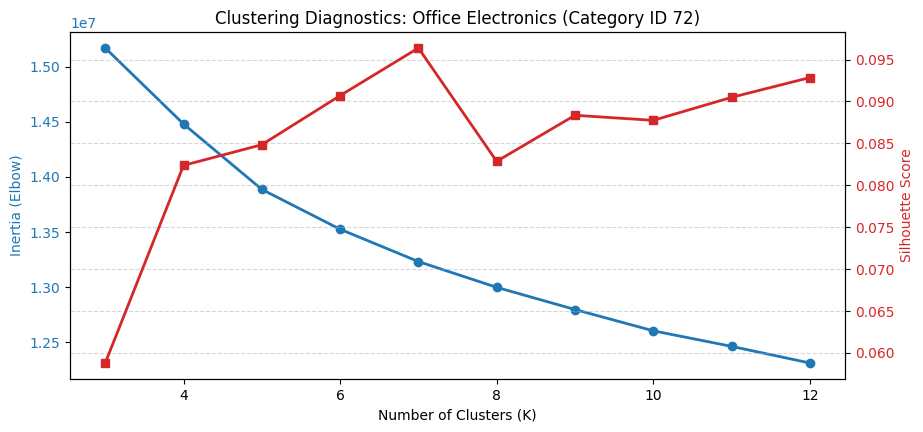

Cluster 0 Verification | Total Listings: 1806


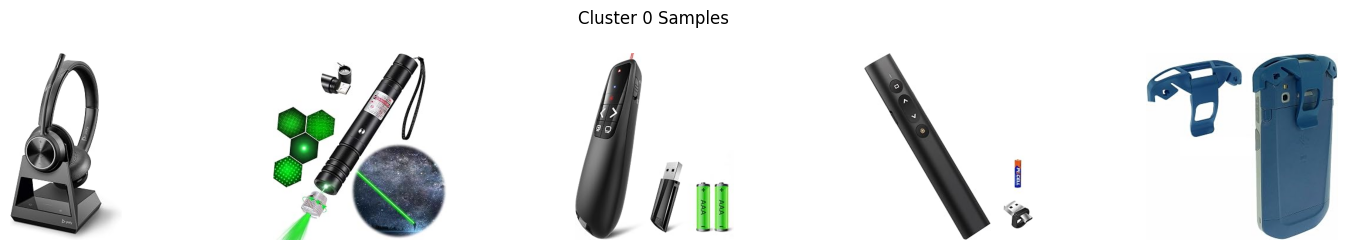

Cluster 1 Verification | Total Listings: 933


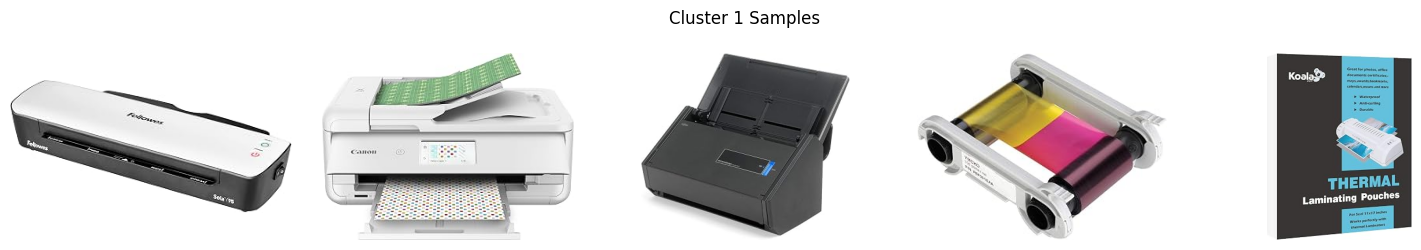

Cluster 2 Verification | Total Listings: 1676


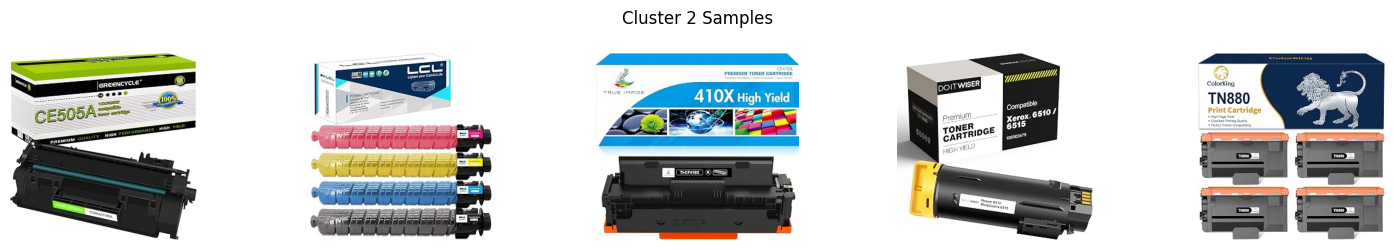

Cluster 3 Verification | Total Listings: 753


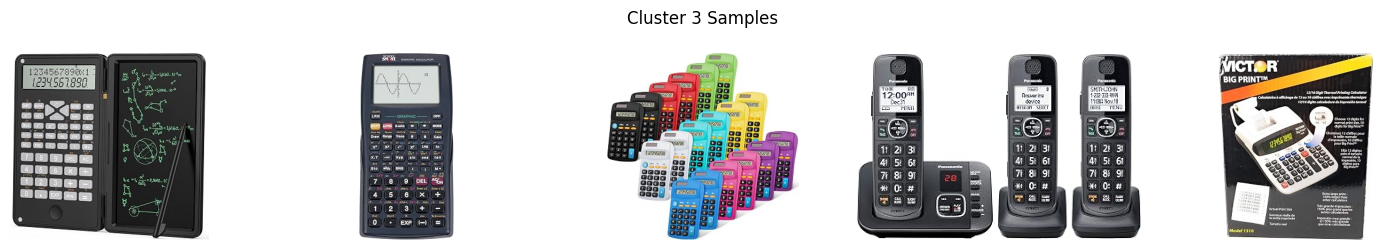

Cluster 4 Verification | Total Listings: 2092


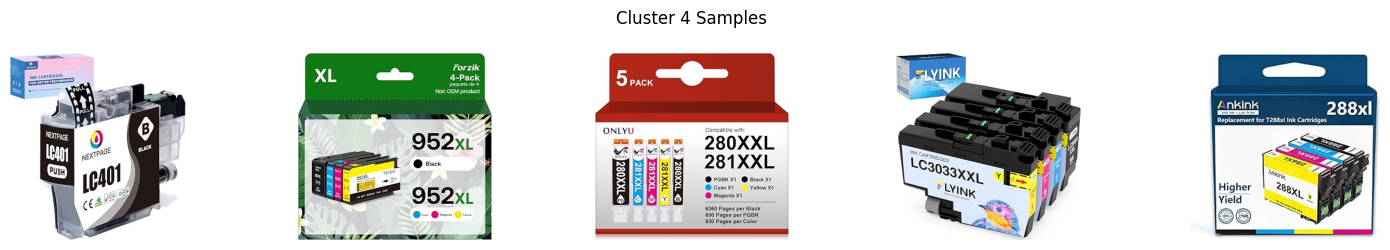

Cluster 5 Verification | Total Listings: 1960


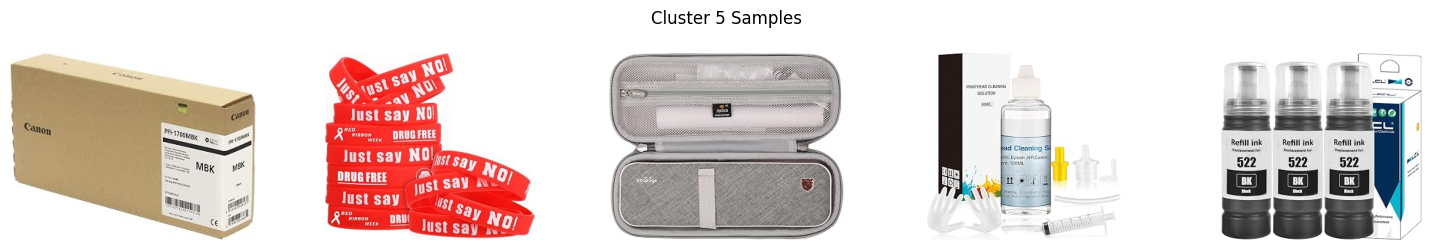

 cluster  n_listings  total_demand_proxy  median_demand_proxy  mean_price  median_price  min_price  max_price  bestseller_count  bestseller_share  a_class_count  a_class_share
       0        1806              163900                  0.0  185.190975         75.99       4.50    11998.0                10          0.005537            172       0.095238
       1         933              170400                 50.0  259.409636        149.99       4.79     4599.0                 5          0.005359            252       0.270096
       2        1676              232350                 50.0   91.866706         59.99       6.99      839.0                 1          0.000597            258       0.153938
       3         753              230000                 50.0   76.573533         44.99       3.59     1095.0                 6          0.007968            140       0.185923
       4        2092              492200                100.0   47.795746         34.99       6.93     2025.0           

In [ ]:
# Running Quantitative Clustering Diagnostics
# Calculate Inertia and Silhouette scores across K = 3 to 12
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use df_product_sub_expanded which already has missing/None embeddings removed
df = df_product_sub_expanded.copy()

# Extract the 384 image embedding columns as feature matrix
feature_cols = [f'image_embedding_{i}' for i in range(384)]
X_embeddings = df[feature_cols].values

k_range = range(3, 13)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_embeddings)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_embeddings, labels))

# Plotting Elbow and Silhouette metrics to find optimal K
fig, ax1 = plt.subplots(figsize=(10, 4.5))

ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (Elbow)', color='tab:blue')
ax1.plot(k_range, inertias, marker='o', color='tab:blue', linewidth=2)
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:red')
ax2.plot(k_range, silhouette_scores, marker='s', color='tab:red', linewidth=2)
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Clustering Diagnostics: Office Electronics (Category ID 72)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Assigning Clusters
CHOICE_K = 6
kmeans = KMeans(n_clusters=CHOICE_K, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_embeddings)

# Displaying sample images from each cluster
for c in range(CHOICE_K):
    cluster_subset = df[df['cluster'] == c]
    print(f"Cluster {c} Verification | Total Listings: {len(cluster_subset)}")

    sample_urls = cluster_subset['imgUrl'].dropna().sample(min(5, len(cluster_subset)), random_state=42).tolist()

    fig, axes = plt.subplots(1, len(sample_urls), figsize=(15, 2.5))
    if len(sample_urls) == 1:
        axes = [axes]

    for idx, url in enumerate(sample_urls):
        try:
            res = requests.get(url, timeout=5)
            img = Image.open(BytesIO(res.content))
            axes[idx].imshow(img)
            axes[idx].axis('off')
        except Exception:
            axes[idx].text(0.5, 0.5, 'Image Load Error', ha='center', va='center')
            axes[idx].axis('off')

    plt.suptitle(f'Cluster {c} Samples', fontsize=12)
    plt.tight_layout()
    plt.show()

# Generating Summary Table
# Computing competition and demand distribution metrics per cluster
cluster_summary = df.groupby('cluster').agg(
    n_listings=('asin', 'count'),
    total_demand_proxy=('boughtInLastMonth', 'sum'),
    median_demand_proxy=('boughtInLastMonth', 'median'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    min_price=('price', 'min'),
    max_price=('price', 'max'),
    bestseller_count=('isBestSeller', lambda x: x.sum()),
    bestseller_share=('isBestSeller', 'mean'),
    a_class_count=('ABC', lambda x: (x == 'A').sum()),
    a_class_share=('ABC', lambda x: (x == 'A').mean())
).reset_index()

print(cluster_summary.to_string(index=False))

5. Predict demand and bestseller status

In [2]:
import pandas as pd
from google.colab import drive

# Set the random seed
SEED = 348

# Mount Google Drive and load the official dataset
drive.mount('/content/drive')
df_product_sub_expanded = pd.read_parquet("/content/drive/MyDrive/SCA Group Proj/office_electronics_cleaned_with_embeddings.parquet")
print(df_product_sub_expanded.shape)

Mounted at /content/drive
(9220, 782)


In [22]:
# 5.1 Features a seller knows before launch, and the 5-fold CV folds (training 80% only)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import Normalizer, StandardScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (mean_absolute_error, mean_squared_error, confusion_matrix,
                             accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score)

# use the shared 80/20 split from Section 3 (test rows = simulated new listings, untouched until the end)
train_df = df_product_sub_expanded[df_product_sub_expanded["split"] == "train"].copy()
test_df = df_product_sub_expanded[df_product_sub_expanded["split"] == "test"].copy()

image_cols = [f"image_embedding_{i}" for i in range(384)]
title_cols = [f"title_embedding_{i}" for i in range(384)]
feature_cols = image_cols + title_cols + ["price"]       # NO reviews, stars, bestseller flag or demand

X_train, X_test = train_df[feature_cols], test_df[feature_cols]
y_train_demand, y_test_demand = train_df["boughtInLastMonth"].to_numpy(), test_df["boughtInLastMonth"].to_numpy()
y_train_revenue, y_test_revenue = train_df["revenue_proxy"].to_numpy(), test_df["revenue_proxy"].to_numpy()
y_train_bestseller = train_df["isBestSeller"].astype(int).to_numpy()
y_test_bestseller = test_df["isBestSeller"].astype(int).to_numpy()

# Preprocessing sits inside the pipeline, so in every CV fold it is fitted on that fold's training rows only.
#  - image and title embeddings: L2-normalized so vector direction (not length) drives similarity
#  - price: log (price is heavily skewed) then z-score standardized
prep = ColumnTransformer([
    ("img", Normalizer(), image_cols),
    ("txt", Normalizer(), title_cols),
    ("price", Pipeline([("log", FunctionTransformer(np.log)), ("z", StandardScaler())]), ["price"]),
])

# how much the planned price counts in the distance, relative to image and title (tuned by CV below)
PRICE_WEIGHTS = [0.0, 0.25, 0.5, 1.0, 2.0]   # wide enough that CV does not pick an edge value
weight_options = [{"img": 1 / np.sqrt(2), "txt": 1 / np.sqrt(2), "price": w} for w in PRICE_WEIGHTS]

# 5 folds, stratified on the rare bestseller flag; the same folds are used for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train_bestseller))
print(f"Training: {len(train_df)} products ({y_train_bestseller.sum()} bestsellers) | Test: {len(test_df)} products ({y_test_bestseller.sum()} bestsellers)")

Training: 7376 products (28 bestsellers) | Test: 1844 products (7 bestsellers)


,K,price_weight,CV_MAE,CV_RMSE
7,10,0.50,215.88,459.39
3,5,1.00,216.25,477.14
8,10,1.00,216.70,460.65
13,15,1.00,216.83,456.68
2,5,0.50,217.03,477.87
12,15,0.50,217.38,454.56
17,25,0.50,217.44,452.76
6,10,0.25,217.47,461.55
18,25,1.00,218.05,454.60
1,5,0.25,218.31,481.80


Selected by 5-fold CV: K = 10, price weight = 0.5 (CV MAE 215.9)
Demand proxy TEST MAE : 217.5
Demand proxy TEST RMSE: 456.0
Benchmark (training mean) TEST MAE: 235.1


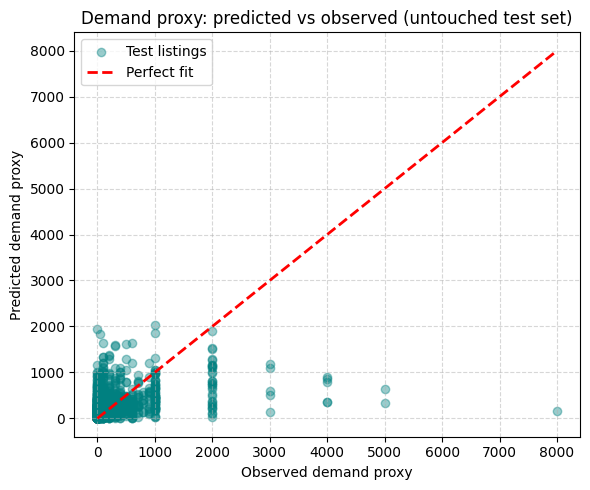

In [23]:
# 5.2 Demand-proxy model: KNN regression. Choose K and the price weight by 5-fold CV, then test once.
# KNN fits the cold-start problem: a new design is forecast from the existing listings it most resembles,
# and those same neighbours are its closest competitors (used again in Section 7).
demand_pipe = Pipeline([("prep", prep), ("knn", KNeighborsRegressor())])
demand_search = GridSearchCV(
    demand_pipe,
    param_grid={"knn__n_neighbors": [5, 10, 15, 25, 50, 100], "prep__transformer_weights": weight_options},
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    refit="MAE",            # MAE: ~40% of listings have zero demand; RMSE would be dominated by a few 9,000-unit sellers
    cv=folds, n_jobs=-1,
)
demand_search.fit(X_train, y_train_demand)

cv_table = pd.DataFrame({
    "K": demand_search.cv_results_["param_knn__n_neighbors"],
    "price_weight": [d["price"] for d in demand_search.cv_results_["param_prep__transformer_weights"]],
    "CV_MAE": -demand_search.cv_results_["mean_test_MAE"],
    "CV_RMSE": -demand_search.cv_results_["mean_test_RMSE"],
}).sort_values("CV_MAE")
display(cv_table.round(2).head(10))

best = demand_search.best_params_
BEST_K = best["knn__n_neighbors"]
BEST_PRICE_W = best["prep__transformer_weights"]["price"]
print(f"Selected by 5-fold CV: K = {BEST_K}, price weight = {BEST_PRICE_W} "
      f"(CV MAE {-demand_search.best_score_:.1f})")

# GridSearchCV refits the selected model on the full 80% training set; now evaluate ONCE on the untouched test set
demand_model = demand_search.best_estimator_
y_pred_demand = demand_model.predict(X_test)
print(f"Demand proxy TEST MAE : {mean_absolute_error(y_test_demand, y_pred_demand):.1f}")
print(f"Demand proxy TEST RMSE: {np.sqrt(mean_squared_error(y_test_demand, y_pred_demand)):.1f}")

# benchmark: predict the training mean for everyone
naive = np.full(len(y_test_demand), y_train_demand.mean())
print(f"Benchmark (training mean) TEST MAE: {mean_absolute_error(y_test_demand, naive):.1f}")

plt.figure(figsize=(6, 5))
plt.scatter(y_test_demand, y_pred_demand, alpha=0.4, color="teal", label="Test listings")
lim = max(y_test_demand.max(), y_pred_demand.max())
plt.plot([0, lim], [0, lim], "r--", lw=2, label="Perfect fit")
plt.xlabel("Observed demand proxy"); plt.ylabel("Predicted demand proxy")
plt.title("Demand proxy: predicted vs observed (untouched test set)")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.tight_layout(); plt.show()

In [24]:
# 5.3 Revenue-proxy model. Rule: predicted revenue = predicted demand x planned price
y_pred_revenue = y_pred_demand * test_df["price"].to_numpy()
print("Revenue proxy rule: [predicted demand proxy] x [planned price]")
print(f"Revenue proxy TEST MAE: {mean_absolute_error(y_test_revenue, y_pred_revenue):,.0f}")

Revenue proxy rule: [predicted demand proxy] x [planned price]
Revenue proxy TEST MAE: 13,812


In [25]:
# 5.4 Bestseller classifier: KNN probability = share of the K nearest training products that are bestsellers.
# Bestsellers are rare (~0.4%), so a 0.5 cutoff would never predict one. Choose K and the probability cutoff by
# 5-fold CV, maximizing balanced accuracy (it weighs the bestseller and non-bestseller classes equally).
clf_rows = []
for k in [5, 10, 15, 25, 50]:
    clf = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=k))])
    clf.set_params(prep__transformer_weights=best["prep__transformer_weights"])   # same distance as the demand model
    oof_proba = cross_val_predict(clf, X_train, y_train_bestseller, cv=folds, method="predict_proba", n_jobs=-1)[:, 1]
    for cutoff in sorted(set(np.round(np.arange(1, k + 1) / k, 4))):
        pred = (oof_proba >= cutoff).astype(int)
        clf_rows.append({"K": k, "cutoff": cutoff,
                         "CV_balanced_accuracy": balanced_accuracy_score(y_train_bestseller, pred),
                         "CV_recall": recall_score(y_train_bestseller, pred, zero_division=0),
                         "CV_precision": precision_score(y_train_bestseller, pred, zero_division=0)})
clf_cv = pd.DataFrame(clf_rows).sort_values("CV_balanced_accuracy", ascending=False)
display(clf_cv.head(8).round(3))

BEST_CLF_K, BEST_CUTOFF = int(clf_cv.iloc[0]["K"]), float(clf_cv.iloc[0]["cutoff"])
print(f"Selected by 5-fold CV: K = {BEST_CLF_K}, launch-as-bestseller cutoff = {BEST_CUTOFF:.3f}")

# refit on the full 80% training set, then evaluate once on the test set
bestseller_model = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=BEST_CLF_K))])
bestseller_model.set_params(prep__transformer_weights=best["prep__transformer_weights"])
bestseller_model.fit(X_train, y_train_bestseller)
bestseller_proba_test = bestseller_model.predict_proba(X_test)[:, 1]
y_pred_bestseller = (bestseller_proba_test >= BEST_CUTOFF).astype(int)

print("--- Bestseller: untouched test set ---")
print("Confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_test_bestseller, y_pred_bestseller))
print(f"Accuracy:          {accuracy_score(y_test_bestseller, y_pred_bestseller):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_bestseller, y_pred_bestseller):.4f}")
print(f"Precision:         {precision_score(y_test_bestseller, y_pred_bestseller, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_test_bestseller, y_pred_bestseller, zero_division=0):.4f}")
print(f"F1 score:          {f1_score(y_test_bestseller, y_pred_bestseller, zero_division=0):.4f}")

,K,cutoff,CV_balanced_accuracy,CV_recall,CV_precision
5,10,0.10,0.574,0.179,0.022
30,25,0.04,0.554,0.179,0.010
0,5,0.20,0.545,0.107,0.022
55,50,0.02,0.526,0.179,0.005
56,50,0.04,0.509,0.036,0.008
8,10,0.40,0.500,0.000,0.000
7,10,0.30,0.500,0.000,0.000
4,5,1.00,0.500,0.000,0.000


Selected by 5-fold CV: K = 10, launch-as-bestseller cutoff = 0.100
--- Bestseller: untouched test set ---
Confusion matrix [[TN FP] [FN TP]]:
[[1781   56]
 [   7    0]]
Accuracy:          0.9658
Balanced accuracy: 0.4848
Precision:         0.0000
Recall:            0.0000
F1 score:          0.0000


6. Recommend initial inventory

In [26]:
# 6.1 Out-of-fold (5-fold CV) demand predictions on the training set -> residuals
# Each training product is predicted by a model that never saw it, so the residuals show the real error on a new listing.
# (runs after Section 5: uses demand_model, folds, X_train, y_train_demand, y_pred_demand, test_df, SEED)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error

oof_pred = cross_val_predict(demand_model, X_train, y_train_demand, cv=folds, n_jobs=-1)   # same K and features as demand_model
oof_resid = y_train_demand - oof_pred                                                        # error e = actual - forecast

print(f"5-fold CV demand MAE : {mean_absolute_error(y_train_demand, oof_pred):.1f}")
print(f"5-fold CV demand RMSE: {np.sqrt(mean_squared_error(y_train_demand, oof_pred)):.1f}")
print("Residual percentiles (5, 25, 50, 75, 95):", np.round(np.percentile(oof_resid, [5, 25, 50, 75, 95]), 1))

5-fold CV demand MAE : 215.9
5-fold CV demand RMSE: 463.1
Residual percentiles (5, 25, 50, 75, 95): [-520. -170.  -55.    0.  470.]


In [27]:
# 6.2 Build a nonnegative 30-day demand scenario distribution for every test product
N_BINS = 10
edges = np.unique(np.quantile(oof_pred, np.linspace(0, 1, N_BINS + 1)))
inner_edges = edges[1:-1]                                   # cut points between bins
train_bin = np.digitize(oof_pred, inner_edges)
resid_by_bin = {b: oof_resid[train_bin == b] for b in np.unique(train_bin)}

# show that the residual spread grows with the prediction (why we bin the residuals)
bin_table = pd.DataFrame({
    "bin": list(resid_by_bin),
    "pred_range": [f"{oof_pred[train_bin == b].min():.0f}-{oof_pred[train_bin == b].max():.0f}" for b in resid_by_bin],
    "n_residuals": [len(r) for r in resid_by_bin.values()],
    "resid_std": [r.std() for r in resid_by_bin.values()],
    "resid_p5": [np.percentile(r, 5) for r in resid_by_bin.values()],
    "resid_p95": [np.percentile(r, 95) for r in resid_by_bin.values()],
}).round(1)
display(bin_table)

test_pred = np.asarray(y_pred_demand, dtype=float)            # point predictions for the test set (Section 5)
test_bin = np.digitize(test_pred, inner_edges)
test_price = test_df["price"].to_numpy(dtype=float)

# one array of equally likely demand scenarios per test product
scenarios = [np.clip(test_pred[i] + resid_by_bin[test_bin[i]], 0, None) for i in range(len(test_df))]

# a pooled-residual version (no bins) is kept for the sensitivity check
scenarios_pooled = [np.clip(test_pred[i] + oof_resid, 0, None) for i in range(len(test_df))]
print("Scenarios per product:", min(len(s) for s in scenarios), "to", max(len(s) for s in scenarios))

# sanity check: how does the scenario mean compare with the point forecast and the historical average?
scen_means = np.array([s.mean() for s in scenarios])
print(f"Average point forecast: {test_pred.mean():.1f} | average scenario mean: {scen_means.mean():.1f} | "
      f"training average demand: {y_train_demand.mean():.1f}")
print("The scenario mean differs from the point forecast because it adds the model's historical CV errors "
      "(which correct any systematic over- or under-forecasting) and floors demand at 0.")

,bin,pred_range,n_residuals,resid_std,resid_p5,resid_p95
0,0,0-15,694,57.5,-15.0,85.0
1,1,20-40,746,86.3,-40.0,160.0
2,2,45-65,708,270.6,-65.0,155.0
3,3,70-95,726,217.9,-95.0,310.0
4,4,100-135,768,262.9,-135.0,378.2
5,5,140-185,769,413.2,-180.0,450.0
6,6,190-245,744,409.9,-230.0,468.5
7,7,250-345,737,484.5,-325.0,671.0
8,8,350-525,737,681.1,-465.0,636.0
9,9,530-2350,747,903.6,-1130.0,1382.0


Scenarios per product: 694 to 769
Average point forecast: 231.9 | average scenario mean: 199.9 | training average demand: 183.6
The scenario mean differs from the point forecast because it adds the model's historical CV errors (which correct any systematic over- or under-forecasting) and floors demand at 0.


In [28]:
# 6.3 Newsvendor quantity Q at the critical ratio, for every test product
C_RATIO = 0.45      # c = 0.45 p
S_RATIO = 0.10      # s = 0.10 c

def evaluate_Q(D, p, Q, c_ratio=C_RATIO, s_ratio=S_RATIO):
    """Expected outcomes of ordering Q units when demand scenarios D are equally likely."""
    c = c_ratio * p
    s = s_ratio * c
    Cu, Co = p - c, c - s
    CR = Cu / (Cu + Co)
    over = np.maximum(Q - D, 0).mean()          # expected unsold units
    short = np.maximum(D - Q, 0).mean()         # expected lost-sale units
    sold = np.minimum(Q, D).mean()
    return {
        "CR": CR, "Q": Q, "unit_cost_c": c, "procurement_spend_cQ": c * Q,
        "exp_sales_units": sold, "exp_unsold_units": over, "exp_short_units": short,
        "exp_overage_cost": Co * over, "exp_shortage_cost": Cu * short,
        "exp_revenue": p * sold, "exp_salvage": s * over,
        "exp_profit": p * sold + s * over - c * Q,
        "P_stockout": (D > Q).mean(),
    }

def newsvendor(D, p, c_ratio=C_RATIO, s_ratio=S_RATIO):
    """Optimal one-time order: Q* = smallest scenario demand whose cumulative probability reaches CR."""
    c = c_ratio * p
    CR = (p - c) / ((p - c) + (c - s_ratio * c))
    Q = float(np.ceil(np.quantile(D, CR, method="inverted_cdf")))   # smallest Q with F(Q) >= CR
    return evaluate_Q(D, p, Q, c_ratio, s_ratio)

rows = []
for i in range(len(test_df)):
    D = scenarios[i]
    r = newsvendor(D, test_price[i])
    r.update({"pred_demand": test_pred[i], "scen_mean": D.mean(),
              "scen_p10": np.percentile(D, 10), "scen_p90": np.percentile(D, 90),
              "P_zero_demand": (D == 0).mean(), "P_demand_ge_50": (D >= 50).mean()})
    rows.append(r)

inv_df = pd.concat([test_df[["asin", "title", "price", "imgUrl"]].reset_index(drop=True),
                    pd.DataFrame(rows)], axis=1)
inv_df["ROI"] = inv_df["exp_profit"] / inv_df["procurement_spend_cQ"].replace(0, np.nan)

print(f"Critical ratio = {inv_df['CR'].iloc[0]:.4f}  (same for every product because c and s scale with p)")
show_cols = ["asin", "title", "price", "pred_demand", "Q", "procurement_spend_cQ",
             "exp_overage_cost", "exp_shortage_cost", "exp_profit", "P_stockout"]
display(inv_df[show_cols].sort_values("exp_profit", ascending=False).head(15).round(2))

# the full table: initial stock and procurement spend for every test product
inv_df.drop(columns=["imgUrl"]).to_csv("inventory_plan_test_products.csv", index=False)
print("Saved inventory_plan_test_products.csv with", len(inv_df), "rows")

Critical ratio = 0.5759  (same for every product because c and s scale with p)


,asin,title,price,pred_demand,Q,procurement_spend_cQ,exp_overage_cost,exp_shortage_cost,exp_profit,P_stockout
44,B0CB7JX3S1,62XL Ink Cartridge Combo Pack Black & Color Re...,42.97,1905.0,1465.0,28327.97,2919.93,8456.33,27737.82,0.42
1470,B0C2C6DC8T,61XL Ink Cartridges Combo Pack Compatible for ...,36.99,1950.0,1510.0,25134.70,2515.38,7279.49,24788.88,0.42
93,B0C8NKM6TS,65XL Ink Cartridges Black and Color Combo Pack...,33.98,2040.0,1600.0,24465.60,2313.64,6687.13,24446.78,0.42
15,B07WDH92NN,"Bonsaii 6-Sheet Micro-Cut Paper Shredder, P-4 ...",39.99,1610.0,1170.0,21054.74,2686.53,7869.88,19398.65,0.42
32,B01E5WS3Q6,EPSON T410 Claria Premium - -Ink High Capacity...,73.29,1190.0,750.0,24735.38,4689.39,14423.19,19174.43,0.42
1042,B0B3Y9LZ8R,LG HU915QB Ultra Short Throw 4K UHD (3840 x 21...,6250.00,15.0,10.0,28125.00,6528.73,51512.97,18980.10,0.42
567,B06XDRZGHZ,Brother Printer LT340CL Optional Lower Paper T...,222.16,525.0,270.0,26992.44,5996.69,32699.80,18850.41,0.42
25,B071WB6BGN,EPSON T702 DURABrite Ultra Ink High Capacity B...,78.99,1140.0,700.0,24881.85,4993.50,15544.93,18636.35,0.42
503,B0BGPL2K77,952XL Newest Upgrade (3 Packs) Compatible 952x...,39.99,1570.0,1130.0,20334.92,2678.51,7869.88,18537.79,0.42
288,B01AD7IK9C,"Brother Monochrome Laser Printer, HL-L6300DW, ...",419.98,335.0,140.0,26458.74,6344.40,38591.15,17378.20,0.42


Saved inventory_plan_test_products.csv with 1844 rows


,base case
test products,"1,844"
products with Q > 0,"1,702"
total units ordered (sum Q),"191,895"
procurement budget (sum cQ),"5,127,007"
expected revenue,"7,342,308"
expected salvage recovery,"182,297"
expected overage cost (Co x unsold),"1,640,672"
expected shortage cost (Cu x lost sales),"9,194,733"
expected mismatch cost (overage + shortage),"10,835,405"
expected profit,"2,397,598"


Check (p-c)E[D] - mismatch = 2,397,598  vs  expected profit = 2,397,598


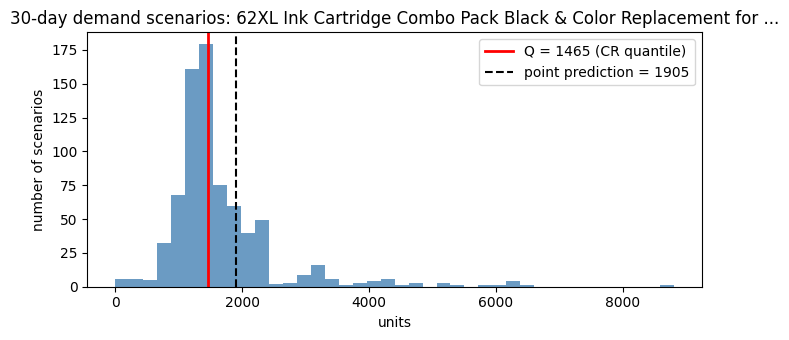

In [29]:
# 6.4 Category totals (base-case assumptions)
totals = pd.Series({
    "test products": len(inv_df),
    "products with Q > 0": int((inv_df["Q"] > 0).sum()),
    "total units ordered (sum Q)": inv_df["Q"].sum(),
    "procurement budget (sum cQ)": inv_df["procurement_spend_cQ"].sum(),
    "expected revenue": inv_df["exp_revenue"].sum(),
    "expected salvage recovery": inv_df["exp_salvage"].sum(),
    "expected overage cost (Co x unsold)": inv_df["exp_overage_cost"].sum(),
    "expected shortage cost (Cu x lost sales)": inv_df["exp_shortage_cost"].sum(),
    "expected mismatch cost (overage + shortage)": inv_df["exp_overage_cost"].sum() + inv_df["exp_shortage_cost"].sum(),
    "expected profit": inv_df["exp_profit"].sum(),
})
display(totals.to_frame("base case").style.format("{:,.0f}"))

# check: profit = (p - c) E[D] - mismatch cost  (shows procurement spend is not double counted)
check = ((inv_df["price"] - inv_df["unit_cost_c"]) * inv_df["scen_mean"]).sum() - totals["expected mismatch cost (overage + shortage)"]
print(f"Check (p-c)E[D] - mismatch = {check:,.0f}  vs  expected profit = {totals['expected profit']:,.0f}")

# example: the scenario distribution and Q for the product with the largest expected profit
ex = inv_df["exp_profit"].idxmax()
plt.figure(figsize=(7, 3.5))
plt.hist(scenarios[ex], bins=40, color="steelblue", alpha=0.8)
plt.axvline(inv_df.loc[ex, "Q"], color="red", lw=2, label=f"Q = {inv_df.loc[ex, 'Q']:.0f} (CR quantile)")
plt.axvline(inv_df.loc[ex, "pred_demand"], color="black", ls="--", label=f"point prediction = {inv_df.loc[ex, 'pred_demand']:.0f}")
plt.title(f"30-day demand scenarios: {inv_df.loc[ex, 'title'][:60]}...")
plt.xlabel("units"); plt.ylabel("number of scenarios"); plt.legend(); plt.tight_layout(); plt.show()

,CR,units (sum Q),budget (sum cQ),exp overage cost,exp shortage cost,exp profit,avg P(stockout)
scenario,,,,,,,
"c = 0.35p, s = 0.10c",0.674,"284,480","$5,907,343","$2,358,618","$9,535,212","$3,745,173",0.30
"c = 0.45p, s = 0.10c",0.576,"191,895","$5,127,007","$1,640,672","$9,194,733","$2,397,598",0.39
"c = 0.55p, s = 0.10c",0.476,"143,290","$4,477,044","$1,144,564","$8,204,479","$1,477,960",0.48
"c = 0.65p, s = 0.10c",0.374,"105,605","$3,621,831","$707,792","$6,894,250","$818,959",0.56
"c = 0.45p, s = 0.00c",0.550,"171,965","$4,455,386","$1,447,188","$9,556,316","$2,229,499",0.42
"c = 0.45p, s = 0.30c",0.636,"240,955","$6,475,947","$1,846,076","$8,541,264","$2,845,662",0.33
"c = 0.45p, s = 0.50c",0.710,"342,385","$9,530,005","$2,351,218","$7,332,639","$3,549,146",0.27
"base costs, Q from pooled residuals (no bands)",0.576,"369,535","$9,303,513","$4,255,738","$7,641,440","$1,335,825",0.35
"base costs, Q from Normal approx. mu + 0.19 x 461",0.576,"591,751","$20,320,244","$12,258,483","$5,044,472","$-4,069,953",0.14


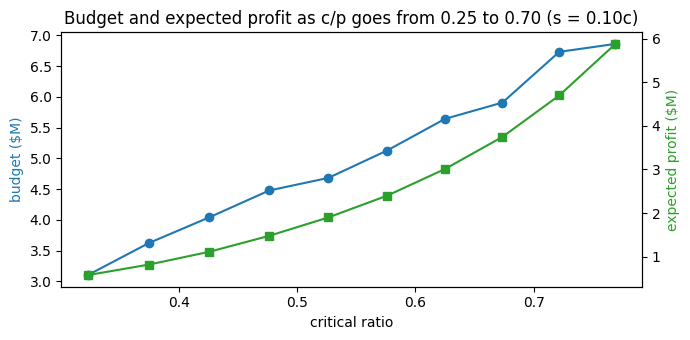

In [37]:
# 6.5 Sensitivity of the plan to the cost assumptions and to the scenario method
def category_totals(c_ratio, s_ratio, scen_list):
    res = pd.DataFrame([newsvendor(scen_list[i], test_price[i], c_ratio, s_ratio) for i in range(len(scen_list))])
    return {"CR": res["CR"].iloc[0], "units (sum Q)": res["Q"].sum(),
            "budget (sum cQ)": res["procurement_spend_cQ"].sum(),
            "exp overage cost": res["exp_overage_cost"].sum(),
            "exp shortage cost": res["exp_shortage_cost"].sum(),
            "exp profit": res["exp_profit"].sum(),
            "avg P(stockout)": res["P_stockout"].mean()}

sens_rows = []
for c_ratio in [0.35, 0.45, 0.55, 0.65]:                 # procurement cost as a share of price
    sens_rows.append({"scenario": f"c = {c_ratio:.2f}p, s = 0.10c", **category_totals(c_ratio, 0.10, scenarios)})
for s_ratio in [0.0, 0.30, 0.50]:                        # recovery value of an unsold unit
    sens_rows.append({"scenario": f"c = 0.45p, s = {s_ratio:.2f}c", **category_totals(0.45, s_ratio, scenarios)})
# Scenario-method checks: choose Q another way, then judge every Q against the same banded scenarios (like-for-like)
def totals_for_Q(label, Q_vec):
    res = pd.DataFrame([evaluate_Q(scenarios[i], test_price[i], Q_vec[i]) for i in range(len(scenarios))])
    return {"scenario": label, "CR": res["CR"].iloc[0], "units (sum Q)": res["Q"].sum(),
            "budget (sum cQ)": res["procurement_spend_cQ"].sum(), "exp overage cost": res["exp_overage_cost"].sum(),
            "exp shortage cost": res["exp_shortage_cost"].sum(), "exp profit": res["exp_profit"].sum(),
            "avg P(stockout)": res["P_stockout"].mean()}

Q_pooled = np.array([newsvendor(scenarios_pooled[i], test_price[i])["Q"] for i in range(len(scenarios_pooled))])
sens_rows.append(totals_for_Q("base costs, Q from pooled residuals (no bands)", Q_pooled))

# Shortcut: Normal approximation Q = mu + z*sigma, with sigma = SD of the CV residuals (one sigma for all products).
# Its Q is then evaluated against our scenario distributions so the cost comparison is like-for-like.
from scipy.stats import norm
CR0 = 0.55 / (0.55 + 0.405)
sigma = oof_resid.std()
Q_normal = np.maximum(0, np.ceil(test_pred + norm.ppf(CR0) * sigma))
sens_rows.append(totals_for_Q(f"base costs, Q from Normal approx. mu + {norm.ppf(CR0):.2f} x {sigma:.0f}", Q_normal))

sens_df = pd.DataFrame(sens_rows).set_index("scenario")
display(sens_df.style.format({"CR": "{:.3f}", "avg P(stockout)": "{:.2f}", "units (sum Q)": "{:,.0f}",
                              "budget (sum cQ)": "${:,.0f}", "exp overage cost": "${:,.0f}",
                              "exp shortage cost": "${:,.0f}", "exp profit": "${:,.0f}"}))

# how the budget and expected profit move as unit cost c/p changes (x-axis shows the resulting critical ratio)
grid = np.linspace(0.25, 0.70, 10)
curve = pd.DataFrame([category_totals(k, 0.10, scenarios) for k in grid], index=grid)
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(curve["CR"], curve["budget (sum cQ)"] / 1e6, "o-", color="tab:blue", label="procurement budget")
ax1.set_xlabel("critical ratio"); ax1.set_ylabel("budget ($M)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(curve["CR"], curve["exp profit"] / 1e6, "s-", color="tab:green", label="expected profit")
ax2.set_ylabel("expected profit ($M)", color="tab:green")
plt.title("Budget and expected profit as c/p goes from 0.25 to 0.70 (s = 0.10c)"); fig.tight_layout(); plt.show()

In [31]:
# 6.6 Holdout back-test (Evaluation only - actual test demand is not used to choose Q)
# Compare realized profit of the newsvendor Q against simply ordering the point forecast.
actual = test_df["boughtInLastMonth"].to_numpy(dtype=float)
p, c = test_price, C_RATIO * test_price
s = S_RATIO * c

def realized_profit(Q):
    return (p * np.minimum(Q, actual) + s * np.maximum(Q - actual, 0) - c * Q).sum()

Q_nv = inv_df["Q"].to_numpy()
Q_point = np.ceil(test_pred)
backtest = pd.DataFrame({
    "policy": ["newsvendor Q (CR quantile)", "order the point forecast"],
    "units ordered": [Q_nv.sum(), Q_point.sum()],
    "procurement spend": [(c * Q_nv).sum(), (c * Q_point).sum()],
    "realized profit": [realized_profit(Q_nv), realized_profit(Q_point)],
    "fill rate": [np.minimum(Q_nv, actual).sum() / actual.sum(), np.minimum(Q_point, actual).sum() / actual.sum()],
    "share of products stocking out": [(actual > Q_nv).mean(), (actual > Q_point).mean()],
})
display(backtest.style.format({"units ordered": "{:,.0f}", "procurement spend": "${:,.0f}",
                               "realized profit": "${:,.0f}", "fill rate": "{:.1%}",
                               "share of products stocking out": "{:.1%}"}))
print(f"Scenario coverage check: actual demand <= Q for {(actual <= Q_nv).mean():.1%} of products (target = CR = {inv_df['CR'].iloc[0]:.1%})")

,policy,units ordered,procurement spend,realized profit,fill rate,share of products stocking out
0,newsvendor Q (CR quantile),"191,895","$5,127,007","$1,078,435",31.6%,39.0%
1,order the point forecast,"427,635","$11,730,733","$-880,565",53.7%,24.5%


Scenario coverage check: actual demand <= Q for 61.0% of products (target = CR = 57.6%)


7. Final Decision

In [32]:
# 7.1 Cluster labels, Training-only cluster statistics, bestseller probabilities
from sklearn.cluster import KMeans

CHOICE_K = 6
# same data, settings and seed as Section 4, so the labels match the Section 4 opportunity map
km = KMeans(n_clusters=CHOICE_K, random_state=42, n_init=10).fit(df_product_sub_expanded[image_cols].values)
cluster_all = pd.Series(km.labels_, index=df_product_sub_expanded.index)
train_df["cluster"] = cluster_all.loc[train_df.index].values
test_df["cluster"] = cluster_all.loc[test_df.index].values

# cluster market summaries computed on the training set only (no test demand used)
cluster_stats = train_df.groupby("cluster").agg(
    train_listings=("asin", "count"),
    total_demand=("boughtInLastMonth", "sum"),
    median_demand=("boughtInLastMonth", "median"),
    median_price=("price", "median"),
    bestseller_share=("isBestSeller", "mean"),
    A_share=("ABC", lambda x: (x == "A").mean()),
)
cluster_stats["demand_per_listing"] = cluster_stats["total_demand"] / cluster_stats["train_listings"]
display(cluster_stats.round(3))

inv_df["cluster"] = test_df["cluster"].values
inv_df["bestseller_prob"] = bestseller_model.predict_proba(X_test)[:, 1]     # KNN vote share from Section 5
inv_df = inv_df.drop(columns=[c for c in inv_df.columns if c.startswith("cluster_")])
inv_df = inv_df.merge(cluster_stats[["train_listings", "demand_per_listing", "A_share"]]
                      .add_prefix("cluster_"), left_on="cluster", right_index=True, how="left")

,train_listings,total_demand,median_demand,median_price,bestseller_share,A_share,demand_per_listing
cluster,,,,,,,
0,1456,139200,0.0,74.990,0.005,0.096,95.604
1,752,136100,50.0,149.990,0.005,0.266,180.984
2,1303,181850,50.0,59.990,0.001,0.154,139.563
3,621,181700,50.0,44.990,0.005,0.179,292.593
4,1686,393500,100.0,34.990,0.001,0.144,233.393
5,1558,321550,50.0,31.985,0.007,0.112,206.386


In [33]:
# 7.2 Nearest competing listings = the K training neighbours the demand model used for each test design
knn_step, prep_step = demand_model.named_steps["knn"], demand_model.named_steps["prep"]
Z_train, Z_test = prep_step.transform(X_train), prep_step.transform(X_test)   # same feature space as the KNN model
nn_dist, nn_idx = knn_step.kneighbors(Z_test)                                 # BEST_K neighbours, nearest first

train_demand = train_df["boughtInLastMonth"].to_numpy()
inv_df["nn_mean_dist"] = nn_dist.mean(axis=1)                         # small distance = many close substitutes (crowded)
inv_df["nn_median_demand"] = np.median(train_demand[nn_idx], axis=1)  # do similar designs actually sell?
inv_df["nn_A_count"] = (train_df["ABC"].to_numpy() == "A")[nn_idx].sum(axis=1)
display(inv_df[["nn_mean_dist", "nn_median_demand", "nn_A_count"]].describe().round(3))

,nn_mean_dist,nn_median_demand,nn_A_count
count,1844.000,1844.000,1844.000
mean,0.738,116.174,1.936
std,0.163,172.409,2.031
min,0.381,0.000,0.000
25%,0.613,0.000,0.000
50%,0.721,50.000,1.000
75%,0.844,150.000,3.000
max,1.316,1500.000,10.000


In [34]:
# 7.3 Screen the test designs, then pick the one with the highest expected newsvendor profit
LAUNCH_UNITS = np.median(y_train_demand)                      # launch threshold = training median demand proxy
inv_df["P_demand_ge_launch"] = [(s >= LAUNCH_UNITS).mean() for s in scenarios]
crowd_cut = inv_df["nn_mean_dist"].quantile(0.25)             # the most crowded quarter of designs

# Section 4 opportunity map: "meaningful demand and fewer close substitutes"
#   = demand per listing at or above the median cluster and no more listings than the median cluster
opportunity = cluster_stats[(cluster_stats["demand_per_listing"] >= cluster_stats["demand_per_listing"].median()) &
                            (cluster_stats["train_listings"] <= cluster_stats["train_listings"].median())].index
print("Opportunity cluster(s) from the training-set map:", list(opportunity))

screens = {
    "1. positive expected profit": inv_df["exp_profit"] > 0,
    f"2. P(demand >= {LAUNCH_UNITS:.0f}) >= 0.5": inv_df["P_demand_ge_launch"] >= 0.5,
    "3. opportunity cluster (Section 4 map)": inv_df["cluster"].isin(opportunity),
    "4. not in the most crowded 25%": inv_df["nn_mean_dist"] > crowd_cut,
}
mask = pd.Series(True, index=inv_df.index)
for name, rule in screens.items():
    mask &= rule
    print(f"{name:45s} -> {mask.sum():5d} designs remain")

cand = inv_df[mask].sort_values("exp_profit", ascending=False)
short_cols = ["asin", "title", "cluster", "price", "pred_demand", "bestseller_prob", "Q",
              "procurement_spend_cQ", "exp_profit", "ROI", "nn_median_demand", "nn_mean_dist"]
display(cand[short_cols].head(10).round(3))
chosen_i = cand.index[0]

Opportunity cluster(s) from the training-set map: [3]
1. positive expected profit                   ->  1702 designs remain
2. P(demand >= 50) >= 0.5                     ->   987 designs remain
3. opportunity cluster (Section 4 map)        ->    87 designs remain
4. not in the most crowded 25%                ->    78 designs remain


,asin,title,cluster,price,pred_demand,bestseller_prob,Q,procurement_spend_cQ,exp_profit,ROI,nn_median_demand,nn_mean_dist
1111,B000Q5XTBQ,"Casio FX 260 Solar II Scientific Calculator, B...",3,23.48,1825.0,0.0,1385.0,14633.910,14130.196,0.966,1000.0,0.736
843,B0B87RGZNP,Auto-Cut Label Maker Machine with Tape PS-100E...,3,79.99,1020.0,0.0,580.0,20877.390,14127.270,0.677,100.0,0.792
208,B0846D5CBP,Casio FX-991ES Plus-2nd Edition Scientific Cal...,3,27.25,1650.0,0.0,1210.0,14837.625,13806.990,0.931,1000.0,0.677
854,B0BBR7HXRB,Vixic D210S Label Makers-Portable Label Maker ...,3,56.99,1090.0,0.0,650.0,16669.575,12027.596,0.722,75.0,0.849
241,B00LI8Q7WI,AT&T TL86103 2-Line Corded/Cordless for Small ...,3,164.99,485.0,0.0,230.0,17076.465,10487.308,0.614,100.0,0.740
565,B098PJJQTP,Casio FC-200V-2 Financial Consultant,3,34.97,1195.0,0.0,755.0,11881.057,9239.349,0.778,150.0,0.922
332,B0089QPMW8,New CASIO Scientific Calculator FX-350ES Plus,3,18.99,1600.0,0.0,1160.0,9912.780,9109.311,0.919,750.0,0.744
962,B00L3LH3O6,Casio Fx-82es Fx82es Plus Bk Display Scientifi...,3,17.00,1650.0,0.0,1210.0,9256.500,8613.535,0.931,1000.0,0.698
741,B082LGR56M,Casio fx-991ES Plus 2 Scientific Calculator wi...,3,29.99,1210.0,0.0,770.0,10391.535,8156.442,0.785,450.0,0.853
1159,B011S51ZN6,Panasonic KX-TGP600 SIP Dect Base Unit & Cordl...,3,204.99,240.0,0.0,110.0,10147.005,6044.780,0.596,100.0,0.773


,Recommended launch
ASIN,B000Q5XTBQ
Title,"Casio FX 260 Solar II Scientific Calculator, B..."
Cluster,3
Planned price p,$23.48
Predicted 30-day demand proxy,1825 units
Demand scenarios P10 / mean / P90,898 / 1575 / 2265
Predicted bestseller probability,0.000 (training base rate 0.004)
Critical ratio,0.576
Initial stock Q,1385 units
Unit cost c,$10.57


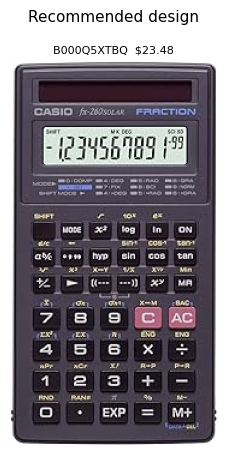

Cluster 3 market (training data):


,train_listings,total_demand,median_demand,median_price,bestseller_share,A_share,demand_per_listing
cluster,,,,,,,
3,621,181700,50.0,44.99,0.005,0.179,292.593


,distance,asin,title,price,boughtInLastMonth,ABC,isBestSeller
7841,0.647,B00AXHBBXU,Casio FX-82MS 2nd Edition Scientific Calculator,16.85,50,C,False
119,0.680,B086Z79HXS,"Casio fx-115ESPLUS2 2nd Edition, Advanced Scie...",16.99,8000,A,False
611,0.727,B08XZRRFM6,Casio fx-300ESPLS2 Blue Scientific Calculator ...,11.49,2000,A,False
436,0.742,B0BSJ33C4R,FX-991CW Advanced Scientific Calculator,19.99,1000,A,False
1570,0.744,B00BGUG72S,Texas Instruments TI-30X IIS 2-Line Scientific...,20.60,500,B,False
383,0.750,B091MJ2GS3,Casio fx-300ESPLS2 Pink Scientific Calculator ...,12.99,3000,A,False
1000,0.762,B00KY3474S,Portable & Gadgets Texas Instruments TI-30X II...,16.99,1000,A,False
1473,0.764,B007HIVMBO,Texas Instruments TI-30X IIS 2-Line Scientific...,24.90,500,B,False
636,0.770,B071R3H9WB,"Casio FX 260 Solar II Scientific Calculator 5""...",9.49,2000,A,False
2578,0.777,B007Q83LVE,Casio DJ-120D Business Desktop Calculator with...,15.55,200,C,False


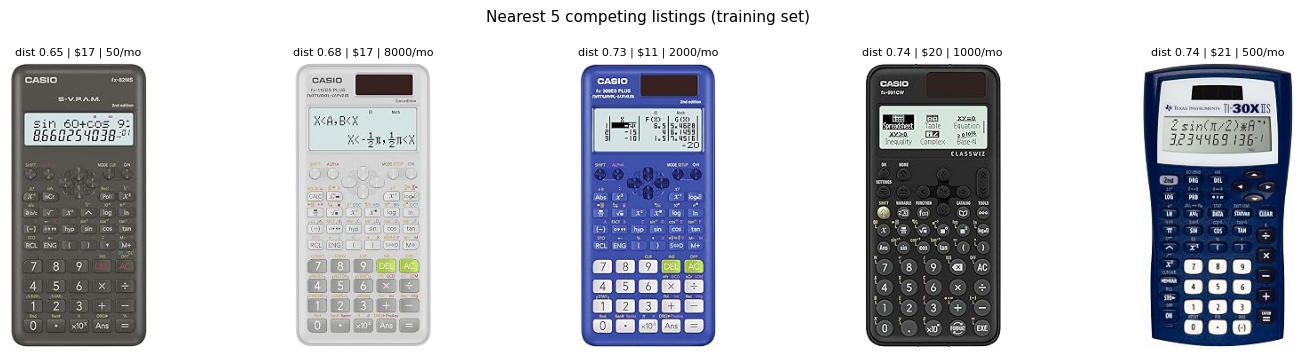

In [35]:
# 7.4 The recommended design: image, cluster, nearest competitors, price, predictions, stock, spend
import requests
from io import BytesIO
from PIL import Image

def show_images(urls, captions, title=None, size=3):
    fig, axes = plt.subplots(1, len(urls), figsize=(size * len(urls), size + 0.6))
    axes = np.atleast_1d(axes)
    for ax, url, cap in zip(axes, urls, captions):
        try:
            img = Image.open(BytesIO(requests.get(url, timeout=5).content)).convert("RGB")
            ax.imshow(img)
        except Exception:
            ax.text(0.5, 0.5, "image unavailable", ha="center", va="center")
        ax.set_title(cap, fontsize=8); ax.axis("off")
    if title: plt.suptitle(title, fontsize=11)
    plt.tight_layout(); plt.show()

pick = inv_df.loc[chosen_i]
pos = inv_df.index.get_loc(chosen_i)                    # row position in the test arrays

summary = pd.Series({
    "ASIN": pick["asin"], "Title": pick["title"], "Cluster": int(pick["cluster"]),
    "Planned price p": f"${pick['price']:,.2f}",
    "Predicted 30-day demand proxy": f"{pick['pred_demand']:.0f} units",
    "Demand scenarios P10 / mean / P90": f"{pick['scen_p10']:.0f} / {pick['scen_mean']:.0f} / {pick['scen_p90']:.0f}",
    "Predicted bestseller probability": f"{pick['bestseller_prob']:.3f}  (training base rate {y_train_bestseller.mean():.3f})",
    "Critical ratio": f"{pick['CR']:.3f}",
    "Initial stock Q": f"{pick['Q']:.0f} units",
    "Unit cost c": f"${pick['unit_cost_c']:,.2f}",
    "Procurement spend cQ": f"${pick['procurement_spend_cQ']:,.0f}",
    "Expected profit (30 days)": f"${pick['exp_profit']:,.0f}",
    "Expected overage / shortage cost": f"${pick['exp_overage_cost']:,.0f} / ${pick['exp_shortage_cost']:,.0f}",
    "P(stockout)": f"{pick['P_stockout']:.2f}",
})
display(summary.to_frame("Recommended launch"))
show_images([pick["imgUrl"]], [f"{pick['asin']}  ${pick['price']:.2f}"], "Recommended design", size=4)

print(f"Cluster {int(pick['cluster'])} market (training data):")
display(cluster_stats.loc[[int(pick["cluster"])]].round(3))

# nearest competing listings: the neighbours the KNN demand model averaged for this design
nn = train_df.iloc[nn_idx[pos]][["asin", "title", "price", "boughtInLastMonth", "ABC", "isBestSeller", "imgUrl"]].copy()
nn.insert(0, "distance", nn_dist[pos])
display(nn.drop(columns="imgUrl").head(10).round(3))   # 10 closest of the K neighbours
show_images(nn["imgUrl"].head(5).tolist(),
            [f"dist {d:.2f} | ${p:.0f} | {u:.0f}/mo" for d, p, u in nn[["distance", "price", "boughtInLastMonth"]].head(5).values],
            "Nearest 5 competing listings (training set)")

Most popular training item: Official Scantron Brand 882-E Answer Sheet. (25 Pack)
  demand proxy 9000/mo, price $8.00, ABC A, bestseller True
Its 20 closest training look-alikes: median demand 200/mo, 10% have zero demand


,Recommended design,Look-alike of top seller
Title,"Casio FX 260 Solar II Scientific Calculator, B...",ScanRite 815-E Scantron Compatible Quiz Sheet....
Cluster,3,5
Price,23.48,9.45
Predicted demand,1825.0,1115.0
Bestseller prob.,0.0,0.1
Initial stock Q,1385.0,675.0
Procurement spend,14633.91,2870.4375
Expected profit,14130.195635,2111.348855
Expected profit / spend,0.965579,0.735549
P(stockout),0.416332,0.416332


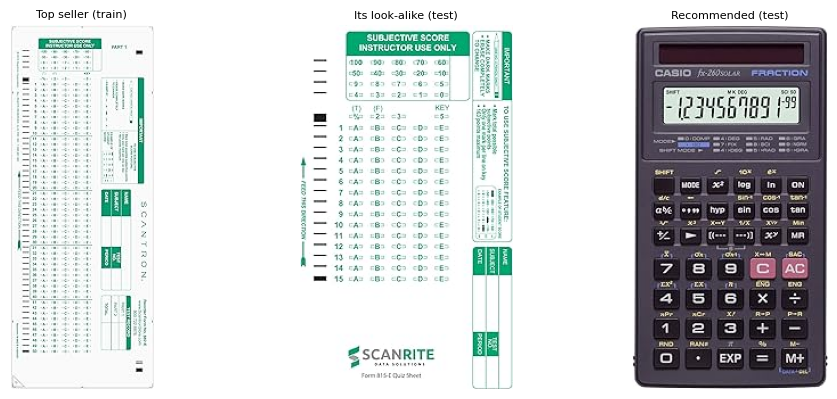

Recommended design: expected profit $14,130 on $14,634 of stock.
Copycat design:     expected profit $2,111 on $2,870 of stock.


In [36]:
# 7.5 Benchmark: "launch a look-alike of the most popular observed item"
top = train_df.sort_values(["boughtInLastMonth", "revenue_proxy"], ascending=False).iloc[0]
top_pos = train_df.index.get_loc(top.name)

# the test design closest to the top seller (the copycat option), in the same KNN feature space
copy_pos = int(np.argmin(np.linalg.norm(Z_test - Z_train[top_pos], axis=1)))
copycat = inv_df.iloc[copy_pos]

# how do other training listings that look like the top seller actually sell?
look_dist, look_idx = knn_step.kneighbors(Z_train[[top_pos]], n_neighbors=21)
look = train_df.iloc[[i for i in look_idx[0] if i != top_pos][:20]]
print(f"Most popular training item: {top['title'][:80]}")
print(f"  demand proxy {top['boughtInLastMonth']:.0f}/mo, price ${top['price']:.2f}, ABC {top['ABC']}, bestseller {bool(top['isBestSeller'])}")
print(f"Its 20 closest training look-alikes: median demand {look['boughtInLastMonth'].median():.0f}/mo, "
      f"{(look['boughtInLastMonth'] == 0).mean():.0%} have zero demand")

cmp_cols = {"title": "Title", "cluster": "Cluster", "price": "Price", "pred_demand": "Predicted demand",
            "bestseller_prob": "Bestseller prob.", "Q": "Initial stock Q", "procurement_spend_cQ": "Procurement spend",
            "exp_profit": "Expected profit", "ROI": "Expected profit / spend", "P_stockout": "P(stockout)",
            "P_zero_demand": "P(zero demand)", "nn_mean_dist": "Mean distance to neighbours (low = crowded)",
            "nn_median_demand": "Neighbours' median demand",
            "cluster_train_listings": "Cluster listings (train)", "cluster_demand_per_listing": "Cluster demand / listing"}
comparison = pd.DataFrame({"Recommended design": pick[list(cmp_cols)],
                           "Look-alike of top seller": copycat[list(cmp_cols)]}).rename(index=cmp_cols)
comparison.loc["Title"] = comparison.loc["Title"].str[:60]
display(comparison)
show_images([top["imgUrl"], copycat["imgUrl"], pick["imgUrl"]],
            ["Top seller (train)", "Its look-alike (test)", "Recommended (test)"], size=3.5)

print(f"Recommended design: expected profit ${pick['exp_profit']:,.0f} on ${pick['procurement_spend_cQ']:,.0f} of stock.")
print(f"Copycat design:     expected profit ${copycat['exp_profit']:,.0f} on ${copycat['procurement_spend_cQ']:,.0f} of stock.")